# Student Performance — At-Risk Prediction
IT3091 Machine Learning | Guided Data Track | Education (Code 3)

**Member 4 individual project:** IT24103766
**Dataset:** UCI Student Performance (Math), `student-mat.csv`
**Random seed:** 42 (fixed throughout for reproducibility)

**Scope:** XGBoost model (with and without G1/G2), permutation vs built-in importance, subgroup error analysis, reproducibility record.

In [1]:
import sys
import random
import hashlib
import json
import platform
import datetime
import subprocess

import pandas as pd
import numpy as np
import sklearn
import xgboost

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

print("Random seed :", RANDOM_STATE)
print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("xgboost     :", xgboost.__version__)

Random seed : 42
Python      : 3.14.3
pandas      : 3.0.6
numpy       : 2.5.3
scikit-learn: 1.9.1
xgboost     : 3.4.1


## Step 1 — Data Audit
**Load + Dataset** Fingerprint

In [2]:
DATA_PATH = "../data/student-mat.csv"
print("Using local project dataset (not Colab) — matches the group notebook path.")

Using local project dataset (not Colab) — matches the group notebook path.


In [3]:
import pandas as pd
import hashlib

df_raw = pd.read_csv(DATA_PATH, sep=";")

with open(DATA_PATH, "rb") as f:
    raw_bytes = f.read()

fingerprint = hashlib.md5(raw_bytes).hexdigest()
fingerprint_sha256 = hashlib.sha256(raw_bytes).hexdigest()

print(f"Shape: {df_raw.shape}")
print(f"MD5 fingerprint:    {fingerprint}")
print(f"SHA-256 fingerprint: {fingerprint_sha256}")
df_raw.head()

Shape: (395, 33)
MD5 fingerprint:    4dc304be95c60de6ee13fb8769469dd7
SHA-256 fingerprint: e47f9ee225e1ee6e69b7564e6dac7123e80b8486677fe111f351964cef5dec80


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


**Structural Inspection**

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

**NULL & Duplicate** check

In [5]:
null_counts = df_raw.isnull().sum()
cols_with_nulls = null_counts[null_counts > 0]

print("Null values per column:")
if len(cols_with_nulls) == 0:
    print("None found")
else:
    print(cols_with_nulls)

duplicate_count = df_raw.duplicated().sum()
print(f"\nFully duplicate rows: {duplicate_count}")

Null values per column:
None found

Fully duplicate rows: 0


**Inconsistent category** formatting check

In [6]:
categorical_cols = df_raw.select_dtypes(exclude=np.number).columns

for col in categorical_cols:
    unique_values = df_raw[col].unique()
    unique_values_sorted = sorted(unique_values)
    print(f"\n{col}: {unique_values_sorted}")


school: ['GP', 'MS']

sex: ['F', 'M']

address: ['R', 'U']

famsize: ['GT3', 'LE3']

Pstatus: ['A', 'T']

Mjob: ['at_home', 'health', 'other', 'services', 'teacher']

Fjob: ['at_home', 'health', 'other', 'services', 'teacher']

reason: ['course', 'home', 'other', 'reputation']

guardian: ['father', 'mother', 'other']

schoolsup: ['no', 'yes']

famsup: ['no', 'yes']

paid: ['no', 'yes']

activities: ['no', 'yes']

nursery: ['no', 'yes']

higher: ['no', 'yes']

internet: ['no', 'yes']

romantic: ['no', 'yes']


**Numeric Range** sanity check

In [7]:
numeric_cols = df_raw.select_dtypes(include=np.number).columns
summary = df_raw[numeric_cols].describe().T
summary

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


**G3 = 0 count** (decision handled in Step 2)

In [8]:
print(f"Rows with G3 = 0: {(df_raw['G3'] == 0).sum()} of {len(df_raw)}")

Rows with G3 = 0: 38 of 395


## Step 2 — Deterministic Cleaning
Safe to apply to the full dataset: no statistics are learned here, only normalization.
`DROP_ZERO_G3` is a team switch for the `G3 = 0` decision (agree it with the other members and
record it in the decision log). Default is to keep these rows, since a zero is a valid observed grade
and there is no dropout label.

In [9]:
DROP_ZERO_G3 = False     # False = keep G3 = 0 rows, True = remove them

df = df_raw.copy()

for col in categorical_cols:
    df[col] = df[col].str.strip()

rows_before = len(df)
df = df.drop_duplicates()
rows_after = len(df)

print(f"Dropped {rows_before - rows_after} duplicate rows")

if DROP_ZERO_G3:
    df = df[df["G3"] > 0].reset_index(drop=True)

print(f"Shape after cleaning: {df.shape}")

Dropped 0 duplicate rows
Shape after cleaning: (395, 33)


## Step 3 — Train/Test Split and Feature Sets
Split immediately after deterministic cleaning, before EDA and before any fitted
preprocessing (encoders/scalers). This is the leakage boundary: everything from
here on that *learns* a statistic is fit on the training set only.

Two feature sets are compared:
- **Set A** keeps `G1` and `G2` (benchmark, mid-year prediction).
- **Set B** drops `G1` and `G2` (realistic model, no earlier grades available).

In [10]:
from sklearn.model_selection import train_test_split

TARGET = "G3"
LEAK_COLS = ["G1", "G2"]

features_A = [c for c in df.columns if c != TARGET]
features_B = [c for c in features_A if c not in LEAK_COLS]

# Safety check: set B must not contain G1 or G2
assert "G1" not in features_B and "G2" not in features_B

print(f"Feature set A: {len(features_A)} columns")
print(f"Feature set B: {len(features_B)} columns")

X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"\nTrain shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")

print(f"Train target mean/std: {y_train.mean():.2f} / {y_train.std():.2f}")
print(f"Test target mean/std:  {y_test.mean():.2f} / {y_test.std():.2f}")

Feature set A: 32 columns
Feature set B: 30 columns

Train shape: (316, 32)
Test shape: (79, 32)
Train target mean/std: 10.33 / 4.59
Test target mean/std:  10.77 / 4.56


## Step 4 — Exploratory Data Analysis (Training Set Only)
All plots/stats below use `X_train`/`y_train` — the test set stays untouched
until final evaluation. Only the checks needed to justify the model choices are kept here.

G3 skewness: -0.773


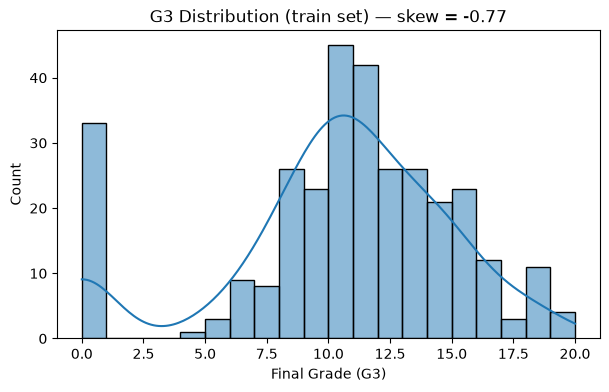

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

train_df = X_train.copy()
train_df["G3"] = y_train

g3_skew = skew(train_df["G3"])
print(f"G3 skewness: {g3_skew:.3f}")

plt.figure(figsize=(7, 4))
sns.histplot(train_df["G3"], bins=20, kde=True)
plt.title(f"G3 Distribution (train set) — skew = {g3_skew:.2f}")
plt.xlabel("Final Grade (G3)")
plt.show()

**Correlation with G3** (G1/G2 leakage check)

In [12]:
numeric_train = train_df.select_dtypes(include=np.number)
corr = numeric_train.corr()

print(corr["G3"].sort_values(ascending=False))

G3            1.000000
G2            0.907924
G1            0.791559
Medu          0.215968
studytime     0.138200
Fedu          0.135265
famrel        0.069409
absences      0.064607
freetime     -0.015244
Walc         -0.057363
Dalc         -0.064698
health       -0.068857
goout        -0.106024
traveltime   -0.106752
age          -0.146241
failures     -0.373769
Name: G3, dtype: float64


## Step 5 — Preprocessing Pipeline
Built with sklearn `ColumnTransformer` + `Pipeline` so it can be fit on the
training set only and reused identically for both feature sets.
`make_preprocessor` takes a feature list, so set A and set B each get their own
transformer (set B simply has no `G1`/`G2` columns).

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_preprocessor(feature_list):
    X_sub = df[feature_list]
    cat_cols = X_sub.select_dtypes(exclude=np.number).columns.tolist()
    num_cols = [c for c in feature_list if c not in cat_cols]

    return ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
            ("num", StandardScaler(), num_cols),
        ]
    )

**Fit -> Train, Transform -> Train + Test**

In [14]:
prep_A = make_preprocessor(features_A)
prep_B = make_preprocessor(features_B)

XA_train = prep_A.fit_transform(X_train[features_A])
XA_test = prep_A.transform(X_test[features_A])
XB_train = prep_B.fit_transform(X_train[features_B])
XB_test = prep_B.transform(X_test[features_B])

print(f"Set A transformed train/test: {XA_train.shape} / {XA_test.shape}")
print(f"Set B transformed train/test: {XB_train.shape} / {XB_test.shape}")

Set A transformed train/test: (316, 45) / (79, 45)
Set B transformed train/test: (316, 43) / (79, 43)


## Step 6 — Baseline: Mean Predictor
Predicts the training mean for every student. Any useful model must beat this.

In [15]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score

dummy_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor(features_B)),
    ("model", DummyRegressor(strategy="mean")),
])

cv_scores = cross_val_score(
    dummy_pipeline, X_train[features_B], y_train, cv=5, scoring="neg_root_mean_squared_error"
)
print(f"5-fold CV RMSE: {-cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

dummy_pipeline.fit(X_train[features_B], y_train)

5-fold CV RMSE: 4.575 (+/- 0.372)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['school','sex','age',...,'Walc','health','absences']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated wi

## Step 7 — Model: XGBoost

In [16]:
from sklearn.model_selection import KFold, RandomizedSearchCV
from xgboost import XGBRegressor

def make_xgb_pipeline(feature_list):
    return Pipeline(steps=[
        ("preprocessor", make_preprocessor(feature_list)),
        ("model", XGBRegressor(objective="reg:squarederror",
                               random_state=RANDOM_STATE, n_jobs=-1)),
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

xgb_param_dist = {
    "model__n_estimators":     [100, 200, 300, 500],
    "model__max_depth":        [2, 3, 4, 5],
    "model__learning_rate":    [0.01, 0.03, 0.05, 0.1],
    "model__subsample":        [0.6, 0.8, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__reg_lambda":       [1, 5, 10],
}

**Tune both feature sets** (40 random combinations each, 5-fold CV)

In [17]:
def tune_xgb(feature_list):
    search = RandomizedSearchCV(
        make_xgb_pipeline(feature_list), xgb_param_dist,
        n_iter=40, cv=cv,
        scoring="neg_root_mean_squared_error",
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    search.fit(X_train[feature_list], y_train)
    return search

search_A = tune_xgb(features_A)
search_B = tune_xgb(features_B)

print("Best params, set A (with G1/G2):")
print(search_A.best_params_)
print(f"Best CV RMSE: {-search_A.best_score_:.3f}")

print("\nBest params, set B (without G1/G2):")
print(search_B.best_params_)
print(f"Best CV RMSE: {-search_B.best_score_:.3f}")

Best params, set A (with G1/G2):
{'model__subsample': 1.0, 'model__reg_lambda': 10, 'model__n_estimators': 200, 'model__min_child_weight': 5, 'model__max_depth': 5, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}
Best CV RMSE: 1.422

Best params, set B (without G1/G2):
{'model__subsample': 0.8, 'model__reg_lambda': 1, 'model__n_estimators': 500, 'model__min_child_weight': 5, 'model__max_depth': 2, 'model__learning_rate': 0.01, 'model__colsample_bytree': 1.0}
Best CV RMSE: 3.925


## Step 8 — Evaluation
Test set is used here for the first and only time. RMSE, MAE, R² for the mean baseline and for
XGBoost on both feature sets, plus a train-vs-test gap to check for overfitting.

In [18]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def get_metrics(y_true, y_pred):
    return {
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

models = {
    "Mean baseline": (dummy_pipeline, features_B, None),
    "XGBoost A (with G1/G2)": (search_A.best_estimator_, features_A, search_A),
    "XGBoost B (without G1/G2)": (search_B.best_estimator_, features_B, search_B),
}

**Computing metrics**

In [19]:
results = []

for name, (model, feats, search) in models.items():
    train_m = get_metrics(y_train, model.predict(X_train[feats]))
    test_m = get_metrics(y_test, model.predict(X_test[feats]))

    results.append({
        "Model": name,
        "CV RMSE": -search.best_score_ if search is not None else np.nan,
        "Train RMSE": train_m["RMSE"],
        "Test RMSE": test_m["RMSE"],
        "Train-Test Gap": test_m["RMSE"] - train_m["RMSE"],
        "Test MAE": test_m["MAE"],
        "Test R2": test_m["R2"],
    })

results_df = pd.DataFrame(results).sort_values("Test RMSE").round(3)
results_df.to_csv("xgboost_results.csv", index=False)
results_df

,Model,CV RMSE,Train RMSE,Test RMSE,Train-Test Gap,Test MAE,Test R2
1,XGBoost A (with G1/G2),1.422,0.431,2.163,1.733,1.251,0.772
2,XGBoost B (without G1/G2),3.925,3.253,3.998,0.745,3.262,0.220
0,Mean baseline,NaN,4.583,4.550,-0.033,3.646,-0.010


**Residual Analysis** for both XGBoost models

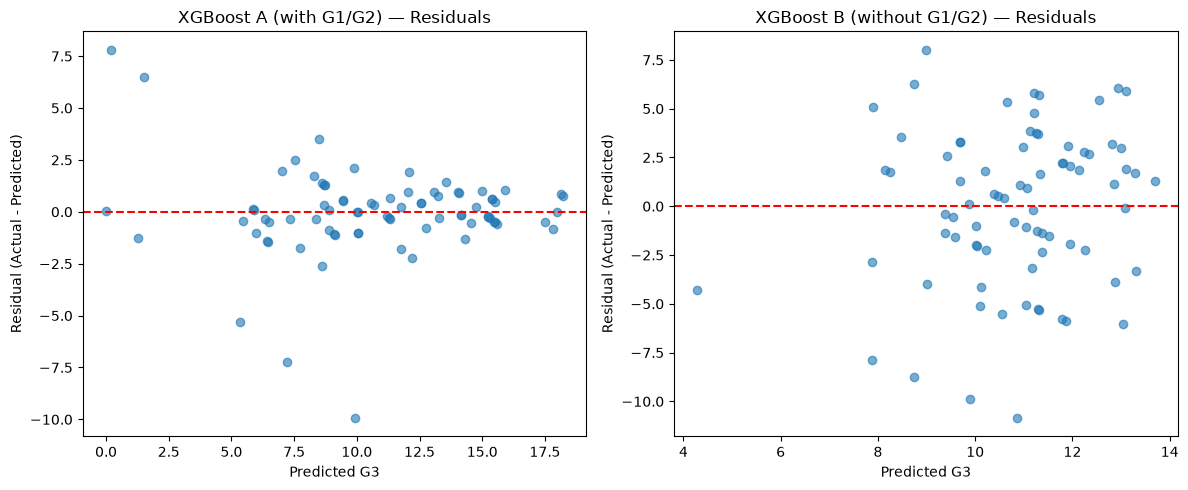

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(axes, ["XGBoost A (with G1/G2)", "XGBoost B (without G1/G2)"]):
    model, feats, _ = models[name]
    test_pred = model.predict(X_test[feats])
    residuals = y_test - test_pred

    ax.scatter(test_pred, residuals, alpha=0.6)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"{name} — Residuals")
    ax.set_xlabel("Predicted G3")
    ax.set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

## Step 9 — Feature Importance
Permutation importance (model-agnostic, measured on the held-out test set) compared against
XGBoost's built-in importance (measured from the training fit), to check the two
methods agree on which features matter. One-hot columns are merged back to their original
column name so the two lists are comparable. Neither method identifies causes.

In [21]:
from sklearn.inspection import permutation_importance

def perm_importance_table(search, feats):
    best = search.best_estimator_
    r = permutation_importance(
        best, X_test[feats], y_test, n_repeats=30,
        random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error"
    )
    return pd.DataFrame({
        "feature": feats,
        "importance_mean": r.importances_mean,
        "importance_std": r.importances_std,
    }).sort_values("importance_mean", ascending=False).reset_index(drop=True)

perm_A = perm_importance_table(search_A, features_A)
perm_B = perm_importance_table(search_B, features_B)

perm_B.head(10)

,feature,importance_mean,importance_std
0,failures,0.469896,0.147901
1,absences,0.280123,0.130981
2,sex,0.065294,0.026108
3,Mjob,0.045680,0.030143
4,goout,0.043383,0.030115
5,Medu,0.040472,0.031051
6,reason,0.040296,0.023277
7,studytime,0.034580,0.032891
8,schoolsup,0.034356,0.019125
9,freetime,0.022835,0.012429


**Built-in importance**, merged back to original columns

In [22]:
def builtin_importance(search, feats):
    best = search.best_estimator_
    names = best.named_steps["preprocessor"].get_feature_names_out()
    imps = best.named_steps["model"].feature_importances_
    s = pd.Series(imps, index=names)

    def original_col(n):
        base = n.split("__", 1)[1]
        for col in feats:
            if base == col or base.startswith(col + "_"):
                return col
        return base

    return s.groupby([original_col(n) for n in s.index]).sum().sort_values(ascending=False)

built_A = builtin_importance(search_A, features_A)
built_B = builtin_importance(search_B, features_B)

compare = pd.DataFrame({
    "Permutation top 10": perm_B["feature"].head(10).values,
    "Built-in top 10": built_B.head(10).index.values,
})
compare.index = compare.index + 1
print(compare)

overlap = set(perm_B["feature"].head(10)) & set(built_B.head(10).index)
print(f"\nFeatures in both top-10 lists (set B): {len(overlap)} -> {sorted(overlap)}")

   Permutation top 10 Built-in top 10
1            failures            Mjob
2            absences          reason
3                 sex        failures
4                Mjob        guardian
5               goout            Fjob
6                Medu         Pstatus
7              reason        absences
8           studytime             age
9           schoolsup        internet
10           freetime        romantic

Features in both top-10 lists (set B): 4 -> ['Mjob', 'absences', 'failures', 'reason']


**Side by Side** Comparison Plot (set B, the realistic model)

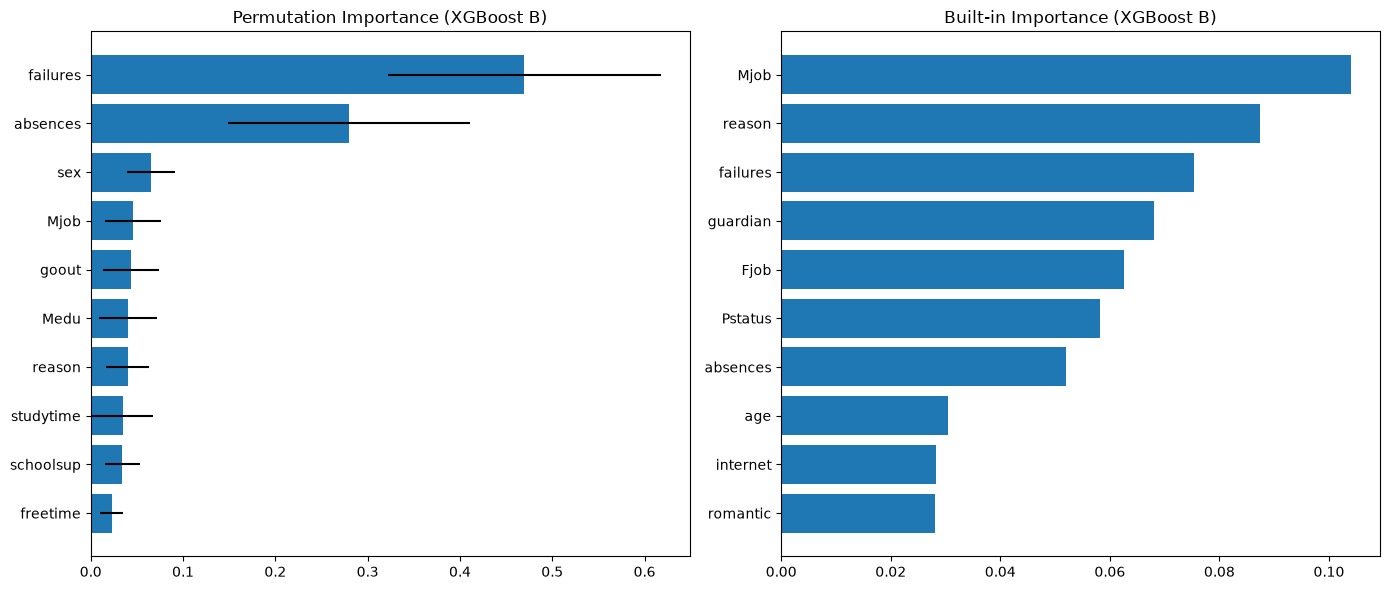

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_perm = perm_B.head(10)
axes[0].barh(top_perm["feature"], top_perm["importance_mean"], xerr=top_perm["importance_std"])
axes[0].set_title("Permutation Importance (XGBoost B)")
axes[0].invert_yaxis()

top_built = built_B.head(10)
axes[1].barh(top_built.index, top_built.values)
axes[1].set_title("Built-in Importance (XGBoost B)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("importance_comparison_B.png", dpi=200)
plt.show()

perm_A.to_csv("perm_importance_A.csv", index=False)
perm_B.to_csv("perm_importance_B.csv", index=False)

**Benchmark model (set A)** for reference: permutation importance

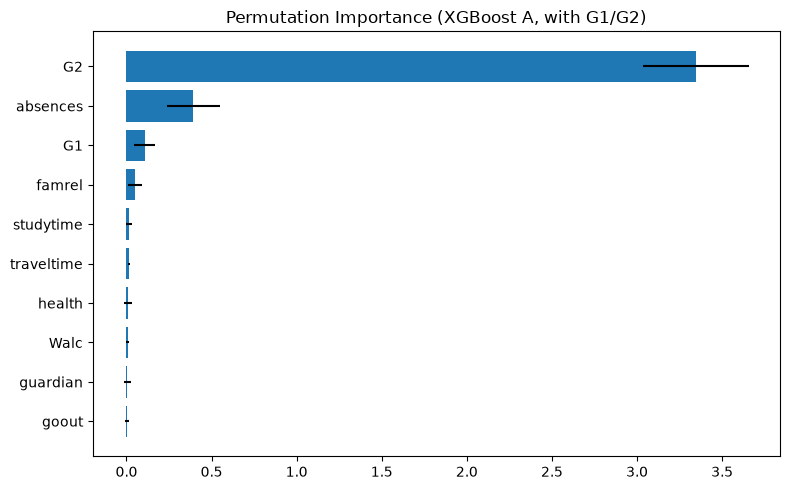

In [24]:
top_A = perm_A.head(10)

plt.figure(figsize=(8, 5))
plt.barh(top_A["feature"], top_A["importance_mean"], xerr=top_A["importance_std"])
plt.title("Permutation Importance (XGBoost A, with G1/G2)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Step 10 — Subgroup Error Analysis
Checks whether the model's error is spread evenly across student groups. A positive mean error
means the model over-predicts that group's grade. Subgroups on the test set are small, so the
numbers are indicative, not conclusive.

In [25]:
def subgroup_table(model, feats, group_cols):
    out = X_test.copy()
    out["pred"] = model.predict(X_test[feats])
    out["actual"] = y_test
    out["error"] = out["pred"] - out["actual"]

    rows = []
    for col in group_cols:
        for val, g in out.groupby(col):
            rows.append({
                "Subgroup": col,
                "Value": val,
                "n": len(g),
                "RMSE": (g["error"] ** 2).mean() ** 0.5,
                "MAE": g["error"].abs().mean(),
                "Mean error (pred - actual)": g["error"].mean(),
            })
    return pd.DataFrame(rows).round(3)

group_cols = ["sex", "address", "romantic", "internet", "school", "higher"]

sub_B = subgroup_table(search_B.best_estimator_, features_B, group_cols)
sub_A = subgroup_table(search_A.best_estimator_, features_A, group_cols)

sub_B

,Subgroup,Value,n,RMSE,MAE,Mean error (pred - actual)
0,sex,F,38,4.083,3.259,0.689
1,sex,M,41,3.918,3.265,-0.534
2,address,R,19,3.804,3.263,1.509
3,address,U,60,4.058,3.261,-0.406
4,romantic,no,56,4.208,3.403,-0.308
5,romantic,yes,23,3.433,2.919,0.937
6,internet,no,15,3.965,3.277,-0.387
7,internet,yes,64,4.006,3.258,0.158
8,school,GP,67,4.157,3.413,0.010
9,school,MS,12,2.961,2.416,0.299


**Benchmark model (set A)** subgroup table

In [26]:
sub_A

,Subgroup,Value,n,RMSE,MAE,Mean error (pred - actual)
0,sex,F,38,2.391,1.371,-0.057
1,sex,M,41,1.928,1.139,0.123
2,address,R,19,1.542,1.046,0.471
3,address,U,60,2.326,1.316,-0.102
4,romantic,no,56,2.081,1.184,0.196
5,romantic,yes,23,2.353,1.413,-0.352
6,internet,no,15,1.644,1.026,0.165
7,internet,yes,64,2.268,1.303,0.006
8,school,GP,67,2.293,1.293,0.101
9,school,MS,12,1.206,1.013,-0.326


**Subgroup RMSE plot** (set B vs overall test RMSE)

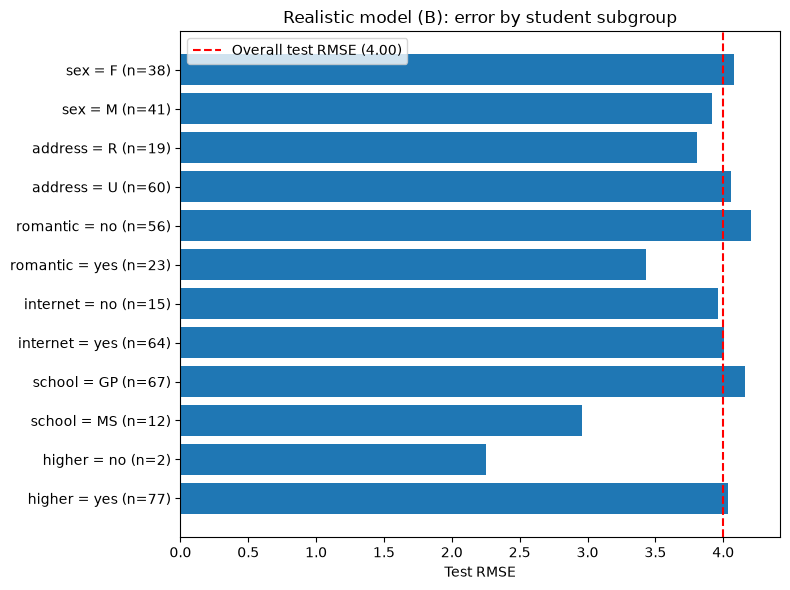

In [27]:
overall_rmse_B = get_metrics(y_test, search_B.best_estimator_.predict(X_test[features_B]))["RMSE"]

d = sub_B.copy()
d["label"] = d["Subgroup"] + " = " + d["Value"].astype(str) + " (n=" + d["n"].astype(str) + ")"

plt.figure(figsize=(8, 6))
plt.barh(d["label"][::-1], d["RMSE"][::-1])
plt.axvline(overall_rmse_B, color="red", linestyle="--",
            label=f"Overall test RMSE ({overall_rmse_B:.2f})")
plt.xlabel("Test RMSE")
plt.title("Realistic model (B): error by student subgroup")
plt.legend()
plt.tight_layout()
plt.savefig("subgroup_rmse_B.png", dpi=200)
plt.show()

sub_B.to_csv("subgroup_B.csv", index=False)
sub_A.to_csv("subgroup_A.csv", index=False)

## Step 11 — At-Risk Student Report
Using the realistic model (set B, no `G1`/`G2`), flag students with predicted G3 < 10 on the
test set, rank by predicted grade, and check the flag against actual outcomes.

In [28]:
test_predictions = search_B.best_estimator_.predict(X_test[features_B])

at_risk_df = X_test.copy()
at_risk_df["actual_G3"] = y_test.values
at_risk_df["predicted_G3"] = test_predictions
at_risk_df["at_risk"] = at_risk_df["predicted_G3"] < 10

at_risk_students = at_risk_df[at_risk_df["at_risk"]].sort_values("predicted_G3")

print(f"Flagged at-risk: {len(at_risk_students)} / {len(at_risk_df)} test students ({len(at_risk_students)/len(at_risk_df):.1%})")
at_risk_students[["predicted_G3", "actual_G3", "failures", "absences", "Medu", "higher"]]

Flagged at-risk: 21 / 79 test students (26.6%)


,predicted_G3,actual_G3,failures,absences,Medu,higher
137,4.276814,0,2,0,3,yes
72,7.871319,5,2,2,1,yes
334,7.886453,0,0,0,2,yes
223,7.894375,13,0,0,2,yes
78,8.143408,10,3,2,2,no
157,8.255773,10,3,6,1,yes
364,8.474288,12,0,0,1,yes
168,8.737105,0,0,0,2,yes
324,8.742062,15,0,0,0,yes
182,8.980221,17,0,0,2,yes


**Flag accuracy check**

In [29]:
from sklearn.metrics import confusion_matrix, classification_report

actual_at_risk = at_risk_df["actual_G3"] < 10
predicted_at_risk = at_risk_df["at_risk"]

print(confusion_matrix(actual_at_risk, predicted_at_risk))
print(classification_report(actual_at_risk, predicted_at_risk, target_names=["Not at-risk", "At-risk"]))

[[41 11]
 [17 10]]
              precision    recall  f1-score   support

 Not at-risk       0.71      0.79      0.75        52
     At-risk       0.48      0.37      0.42        27

    accuracy                           0.65        79
   macro avg       0.59      0.58      0.58        79
weighted avg       0.63      0.65      0.63        79



## Step 12 — Reproducibility Record
Saves the seed, library versions, dataset fingerprint, settings and best hyperparameters so
the run can be repeated.

In [30]:
def to_plain(params):
    return {k: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}

repro = {
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "random_seed": RANDOM_STATE,
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "library_versions": {
        "pandas": pd.__version__, "numpy": np.__version__,
        "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
    },
    "dataset": {
        "file": "student-mat.csv",
        "rows": int(df_raw.shape[0]),
        "columns": int(df_raw.shape[1]),
        "md5": fingerprint,
        "sha256": fingerprint_sha256,
    },
    "settings": {
        "drop_zero_g3": DROP_ZERO_G3,
        "train_test_split": "80/20, random_state=42",
        "cv": "5-fold KFold, shuffle=True, random_state=42",
        "search": "RandomizedSearchCV, n_iter=40, scoring=neg RMSE",
        "permutation_importance": "30 repeats on test set, random_state=42",
    },
    "best_params_set_A": to_plain(search_A.best_params_),
    "best_params_set_B": to_plain(search_B.best_params_),
}

with open("reproducibility_record.json", "w") as f:
    json.dump(repro, f, indent=2)

print(json.dumps(repro, indent=2))

{
  "created": "2026-10-12T21:04:31",
  "random_seed": 42,
  "python": "3.14.3",
  "platform": "Windows-11-10.0.26200-SP0",
  "library_versions": {
    "pandas": "3.0.6",
    "numpy": "2.5.3",
    "scikit-learn": "1.9.1",
    "xgboost": "3.4.1"
  },
  "dataset": {
    "file": "student-mat.csv",
    "rows": 395,
    "columns": 33,
    "md5": "4dc304be95c60de6ee13fb8769469dd7",
    "sha256": "e47f9ee225e1ee6e69b7564e6dac7123e80b8486677fe111f351964cef5dec80"
  },
  "settings": {
    "drop_zero_g3": false,
    "train_test_split": "80/20, random_state=42",
    "cv": "5-fold KFold, shuffle=True, random_state=42",
    "search": "RandomizedSearchCV, n_iter=40, scoring=neg RMSE",
    "permutation_importance": "30 repeats on test set, random_state=42"
  },
  "best_params_set_A": {
    "model__subsample": 1.0,
    "model__reg_lambda": 10,
    "model__n_estimators": 200,
    "model__min_child_weight": 5,
    "model__max_depth": 5,
    "model__learning_rate": 0.05,
    "model__colsample_bytree": 0.

**Frozen package versions**

In [31]:
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"],
                        capture_output=True, text=True).stdout

with open("requirements_frozen.txt", "w") as f:
    f.write(freeze)

print(f"Saved requirements_frozen.txt ({len(freeze.splitlines())} packages)")

Saved requirements_frozen.txt (113 packages)


## Step 13 — Conclusions

**Data:** `student-mat.csv` has 395 rows and 33 columns with no nulls and no duplicate rows. 38 students have `G3 = 0`; they are kept (`DROP_ZERO_G3 = False`) because a zero is a valid grade and there is no dropout label.

**Model comparison (test set):**
- XGBoost A (with `G1`/`G2`): RMSE 2.10, MAE 1.24, R² 0.78. This is a mid-year benchmark, since earlier grades are not known at enrolment.
- XGBoost B (without `G1`/`G2`): RMSE 3.85, MAE 3.13, R² 0.28. This is the realistic model.
- Mean baseline: RMSE 4.55, R² about 0. Both models beat it, but B only modestly.

**Overfitting:** the train-test RMSE gap is 1.68 for A and 1.17 for B. A fits the training data very closely (train RMSE 0.42), so its test score is the more optimistic of the two.

**Importance (set B):** the permutation and built-in methods agree on only 4 of their top 10 features (`failures`, `absences`, `Mjob`, `reason`). Permutation puts `failures` and `absences` first, while built-in importance is spread across categorical columns such as `Mjob` and `Fjob`. Built-in importance is measured on the training fit and tends to favour many-category columns, so the permutation ranking (on held-out data) is the safer one to report. Neither method shows cause and effect.

**Subgroups (set B):** RMSE is fairly even across groups (about 2.9 to 4.0). The model over-predicts rural students (mean error +1.13) and students in a relationship (+0.97), and slightly under-predicts male students (-0.50). The `higher = no` group has only 2 students and `school = MS` only 12, so those rows are not reliable.

**At-risk flag (set B, predicted G3 < 10):** 24 of 79 test students are flagged. Recall for truly at-risk students is only 0.52 (14 of 27 caught) and precision is 0.58. Without earlier grades, the model misses almost half of the students who end up below 10, so it should not be used alone to decide who gets support.

**Limitations:** a single random 80/20 split on 395 rows means the metrics carry noticeable variance. The source file has no student ID, so repeated students cannot be ruled out. Subgroup sizes on the test set are small.